# MEDE · CP3 · Relații și protocol experimental
**Simon Alessia · U20 · Localitatea / UAT (UAT × An) · Județul Prahova**

**Întrebarea de explorare:** Care localități cresc teritorial (suprafață construită) fără să înregistreze o creștere a populației?

**Surse:** Eurostat (populație, 2010–2025, pas 5 ani) + GHSL (suprafață construită, km²).
**Unitate:** UAT × An — 104 UAT-uri, 4 momente de timp (2010, 2015, 2020, 2025).

### Ce face acest notebook (cerințele CP3)
1. **Harta relațiilor** dintre cele două surse: corelație Spearman, informație mutuală, corelație cu lag, CCA (cu test de permutare), graf kNN de similaritate.
2. **Protocolul experimental** (identic pentru toate metodele): split, metrici, seed-uri, subperioade.
3. **PCA ca baseline** vs. **t-SNE și Autoencoder**, aplicate pe fiecare sursă separat (Pop, Built) și pe datele combinate (Pop+Built), în două spații de trăsături: *niveluri* (matricea X din CP2) și *dinamică* (ritmuri de creștere).

> Rulare: local sau în Colab. Datele se citesc din `data/`; dacă folderul lipsește (Colab), se cere încărcarea celor două CSV-uri.

In [1]:
import os, re, unicodedata, warnings, itertools, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.spatial.distance import pdist
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors
from sklearn.cross_decomposition import CCA
from sklearn.feature_selection import mutual_info_regression

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

# ---------------- Configurație globală a protocolului ----------------
SEEDS     = list(range(10))   # 10 seed-uri (>= 5 cerut)
K_DIM     = 2                 # nr. de dimensiuni păstrate (2 = figură; decizia k se rafinează la CP4)
KNN       = 5                 # vecini pentru trustworthiness / continuity / graf kNN
TEST_SIZE = 0.20              # split aleator 80/20 pe UAT-uri (fit doar pe train)
METHODS   = ["PCA", "t-SNE", "Autoencoder"]

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)
print("Config:", dict(SEEDS=len(SEEDS), K_DIM=K_DIM, KNN=KNN, TEST_SIZE=TEST_SIZE, METHODS=METHODS))

Config: {'SEEDS': 10, 'K_DIM': 2, 'KNN': 5, 'TEST_SIZE': 0.2, 'METHODS': ['PCA', 't-SNE', 'Autoencoder']}


## 1. Încărcare și aliniere (continuitate cu CP1/CP2)
Aceeași aliniere ca la CP2: cheie de nume normalizată (fără diacritice și prefixe), `inner join` Eurostat ↔ GHSL, format lat (1 rând = 1 UAT × 4 ani).

In [2]:
EUROSTAT, GHSL = "Eurostat_Prahova_2010_2025.csv", "GHSL_Prahova_2010_2025_CP2.csv"
if os.path.exists(os.path.join("data", EUROSTAT)):
    p_e, p_g = os.path.join("data", EUROSTAT), os.path.join("data", GHSL)
else:                                  # fallback Colab
    from google.colab import files
    up = files.upload(); p_e = next(f for f in up if "eurostat" in f.lower()); p_g = next(f for f in up if "ghsl" in f.lower())

eu, gh = pd.read_csv(p_e), pd.read_csv(p_g)

def normalize_name(s):
    s = unicodedata.normalize("NFKD", str(s).lower().strip()).encode("ascii", "ignore").decode("ascii")
    s = re.sub(r"^(municipiul|orasul|oras|comuna)\s+", "", s)
    return re.sub(r"[^a-z0-9]", "", s)

eu["key"], gh["key"] = eu["UAT_Name"].map(normalize_name), gh["name"].map(normalize_name)
gw = gh.pivot_table(index="key", columns="An", values="Built_km2", aggfunc="mean")
gw.columns = [f"Built_{c}" for c in gw.columns]
df = eu.merge(gw.reset_index(), on="key", how="inner").reset_index(drop=True)

assert len(df) == 104 and df["key"].is_unique, "alinierea trebuie să producă 104 UAT-uri unice"
assert df.filter(regex="^(Pop|Built)_").notna().all().all()
print("UAT-uri aliniate:", len(df), "| neasociate:", len(eu) - len(df))

# Trăsături: niveluri (matricea X din CP2) și dinamică (log-rata de creștere pe interval de 5 ani)
YEARS = [2010, 2015, 2020, 2025]
INTV  = list(zip(YEARS[:-1], YEARS[1:]))
for a, b in INTV:
    df[f"dPop_{a}_{b}"]   = np.log(df[f"Pop_{b}"]   / df[f"Pop_{a}"])
    df[f"dBuilt_{a}_{b}"] = np.log(df[f"Built_{b}"] / df[f"Built_{a}"])
df["dPop_tot"]   = np.log(df["Pop_2025"]   / df["Pop_2010"])
df["dBuilt_tot"] = np.log(df["Built_2025"] / df["Built_2010"])
df["gap"]        = df["dBuilt_tot"] - df["dPop_tot"]          # indice de "decuplare": construit minus populație

SPACES = {
    "Niveluri": {"Pop":   [f"Pop_{y}" for y in YEARS],
                 "Built": [f"Built_{y}" for y in YEARS]},
    "Dinamică": {"Pop":   [f"dPop_{a}_{b}" for a, b in INTV],
                 "Built": [f"dBuilt_{a}_{b}" for a, b in INTV]},
}
for sp in SPACES: SPACES[sp]["Pop+Built"] = SPACES[sp]["Pop"] + SPACES[sp]["Built"]

def view_cols(space, view, window=None):
    # Coloanele unei vederi; window ∈ {None,'P1','P2'} = prima / ultima subperioadă (n_t-1 momente)
    if view == "Pop+Built":
        return view_cols(space, "Pop", window) + view_cols(space, "Built", window)
    c = SPACES[space][view]
    return c if window is None else (c[:-1] if window == "P1" else c[1:])

for sp in SPACES:
    print(f"{sp:9s}", {v: len(view_cols(sp, v)) for v in ["Pop", "Built", "Pop+Built"]}, "trăsături")

pop_down_built_up = ((df.Pop_2025 < df.Pop_2010) & (df.Built_2025 > df.Built_2010))
print(f"\nUAT cu populație în scădere ȘI construit în creștere (2010→2025): {pop_down_built_up.sum()} din {len(df)} ({pop_down_built_up.mean():.0%})")
print(f"Construit în creștere 2010→2025: {(df.Built_2025 > df.Built_2010).sum()}/104 | monoton nedescrescător pe toate intervalele: {(np.diff(df[SPACES['Niveluri']['Built']].values, axis=1) >= 0).all(1).sum()}/104")
print("⇒ criteriul binar „construit↑ & populație↓” se reduce practic la „populație↓”; folosim indicele continuu gap = Δlog(construit) − Δlog(populație) și un prag relativ.")

UAT-uri aliniate: 104 | neasociate: 0
Niveluri  {'Pop': 4, 'Built': 4, 'Pop+Built': 8} trăsături
Dinamică  {'Pop': 3, 'Built': 3, 'Pop+Built': 6} trăsături

UAT cu populație în scădere ȘI construit în creștere (2010→2025): 96 din 104 (92%)
Construit în creștere 2010→2025: 104/104 | monoton nedescrescător pe toate intervalele: 104/104
⇒ criteriul binar „construit↑ & populație↓” se reduce practic la „populație↓”; folosim indicele continuu gap = Δlog(construit) − Δlog(populație) și un prag relativ.


## 1b. De la CP2 (niveluri) la CP3 (niveluri + dinamică): de ce două spații
La CP2 am lucrat pe **niveluri** (Pop_t și Built_t, 8 trăsături) ca să avem o referință: PCA a arătat că PC1 (≈95%) reflectă *mărimea* UAT-ului (Ploiești domină). Asta e un rezultat util, dar nu răspunde întrebării, care privește **creșterea**, nu mărimea. De aceea la CP3 comparăm reprezentările în ambele spații:
- **Niveluri** — continuitate cu CP2 (matricea X neschimbată);
- **Dinamică** — log-rate de creștere pe intervale de 5 ani (Pop și Built separat), unde mărimea UAT-ului dispare și rămâne ritmul de schimbare.
Nu schimbăm întrebarea; schimbăm reprezentarea în care o citim.

## 2. Harta relațiilor între surse (Pop ↔ Built)
Măsurăm legăturile în două spații: **niveluri** (mărime absolută — dominată de dimensiunea UAT) și **dinamică** (log-rate de creștere — informația care răspunde întrebării).
Instrumente: corelație Spearman (robustă la valorile extreme, ex. Ploiești), informație mutuală (kNN), corelație cu lag, CCA cu test de permutare, acord între grafurile kNN ale celor două surse.

In [3]:
# ---- (a) Corelații Spearman ----
lev_cols = SPACES["Niveluri"]["Pop+Built"]
R_lev = df[lev_cols].corr(method="spearman")
rho_same = {y: stats.spearmanr(df[f"Pop_{y}"], df[f"Built_{y}"])[0] for y in YEARS}
print("Spearman Pop_t vs Built_t (niveluri):", {y: round(v, 3) for y, v in rho_same.items()})

# ---- (b) Dinamică: Pop(interval i) × Built(interval j); diagonala = sincron, în afara ei = lag ----
dP, dB = SPACES["Dinamică"]["Pop"], SPACES["Dinamică"]["Built"]
lag_corr = pd.DataFrame([[stats.spearmanr(df[p], df[b])[0] for b in dB] for p in dP],
                        index=[f"ΔPop {a}–{b}" for a, b in INTV], columns=[f"ΔBuilt {a}–{b}" for a, b in INTV])
display(lag_corr.round(3))

# ---- (c) Informație mutuală (kNN) ----
def mi_cross(A, B, seed=0):
    return np.array([mutual_info_regression(A, B[:, j], n_neighbors=5, random_state=seed) for j in range(B.shape[1])]).T

MI_dyn = pd.DataFrame(mi_cross(StandardScaler().fit_transform(df[dP]), StandardScaler().fit_transform(df[dB])),
                      index=lag_corr.index, columns=lag_corr.columns)
MI_lev = mi_cross(StandardScaler().fit_transform(np.log(df[SPACES["Niveluri"]["Pop"]])),
                  StandardScaler().fit_transform(np.log(df[SPACES["Niveluri"]["Built"]])))
print("MI medie niveluri (log):", round(MI_lev.mean(), 3), "| MI medie dinamică:", round(MI_dyn.values.mean(), 3))

# ---- (d) CCA: corelații canonice (SVD pe baze ortonormale) + test de permutare ----
def canon_corr(A, B):
    A = A - A.mean(0); B = B - B.mean(0)
    Qa, _ = np.linalg.qr(A); Qb, _ = np.linalg.qr(B)
    return np.linalg.svd(Qa.T @ Qb, compute_uv=False)

rng = np.random.default_rng(0)
cca_rows = []
for sp in SPACES:
    A = StandardScaler().fit_transform(df[SPACES[sp]["Pop"]]); B = StandardScaler().fit_transform(df[SPACES[sp]["Built"]])
    r = canon_corr(A, B)
    null = np.array([canon_corr(A, B[rng.permutation(len(B))])[0] for _ in range(500)])
    # corelație canonică 1 validată pe test (fit pe train) — 10 split-uri
    cv = []
    for s in SEEDS:
        tr, te = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, random_state=s)
        sa, sb = StandardScaler().fit(df.iloc[tr][SPACES[sp]["Pop"]]), StandardScaler().fit(df.iloc[tr][SPACES[sp]["Built"]])
        m = CCA(n_components=1, scale=False, max_iter=2000).fit(sa.transform(df.iloc[tr][SPACES[sp]["Pop"]]), sb.transform(df.iloc[tr][SPACES[sp]["Built"]]))
        u, v = m.transform(sa.transform(df.iloc[te][SPACES[sp]["Pop"]]), sb.transform(df.iloc[te][SPACES[sp]["Built"]]))
        cv.append(np.corrcoef(u[:, 0], v[:, 0])[0, 1])
    cca_rows.append(dict(spatiu=sp, r1=r[0], r2=r[1], null95=np.percentile(null, 95), p_perm=(1 + (null >= r[0]).sum()) / 501,
                         r1_test_medie=np.mean(cv), r1_test_std=np.std(cv, ddof=1)))
cca_tab = pd.DataFrame(cca_rows).set_index("spatiu")
display(cca_tab.round(3))

# ---- (e) Graf kNN de similaritate: cât de mult coincid vecinii văzuți din Pop vs. din Built? ----
def knn_idx(Z, k=KNN):
    return NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
def jaccard(A, B):
    return np.mean([len(set(a) & set(b)) / len(set(a) | set(b)) for a, b in zip(A, B)])

knn_rows = []
for sp in SPACES:
    Gp = knn_idx(StandardScaler().fit_transform(df[SPACES[sp]["Pop"]])); Gb = knn_idx(StandardScaler().fit_transform(df[SPACES[sp]["Built"]]))
    rnd = np.mean([jaccard(Gp, np.array([rng.choice(np.delete(np.arange(len(df)), i), KNN, replace=False) for i in range(len(df))])) for _ in range(50)])
    knn_rows.append(dict(spatiu=sp, jaccard_Pop_vs_Built=jaccard(Gp, Gb), jaccard_aleator=rnd))
knn_tab = pd.DataFrame(knn_rows).set_index("spatiu")
display(knn_tab.round(3))

for nm, t in [("relatii_cca", cca_tab), ("relatii_knn", knn_tab), ("relatii_lag_spearman", lag_corr), ("relatii_mi_dinamica", MI_dyn)]:
    t.to_csv(f"results/{nm}.csv")

Spearman Pop_t vs Built_t (niveluri): {2010: np.float64(0.943), 2015: np.float64(0.942), 2020: np.float64(0.941), 2025: np.float64(0.946)}


,ΔBuilt 2010–2015,ΔBuilt 2015–2020,ΔBuilt 2020–2025
ΔPop 2010–2015,0.497,0.475,0.475
ΔPop 2015–2020,0.299,0.293,0.434
ΔPop 2020–2025,0.589,0.487,0.511


MI medie niveluri (log): 1.149 | MI medie dinamică: 0.135


,r1,r2,null95,p_perm,r1_test_medie,r1_test_std
spatiu,,,,,,
Niveluri,0.986,0.803,0.549,0.002,0.883,0.087
Dinamică,0.661,0.287,0.373,0.002,0.611,0.177


,jaccard_Pop_vs_Built,jaccard_aleator
spatiu,,
Niveluri,0.114,0.028
Dinamică,0.046,0.027


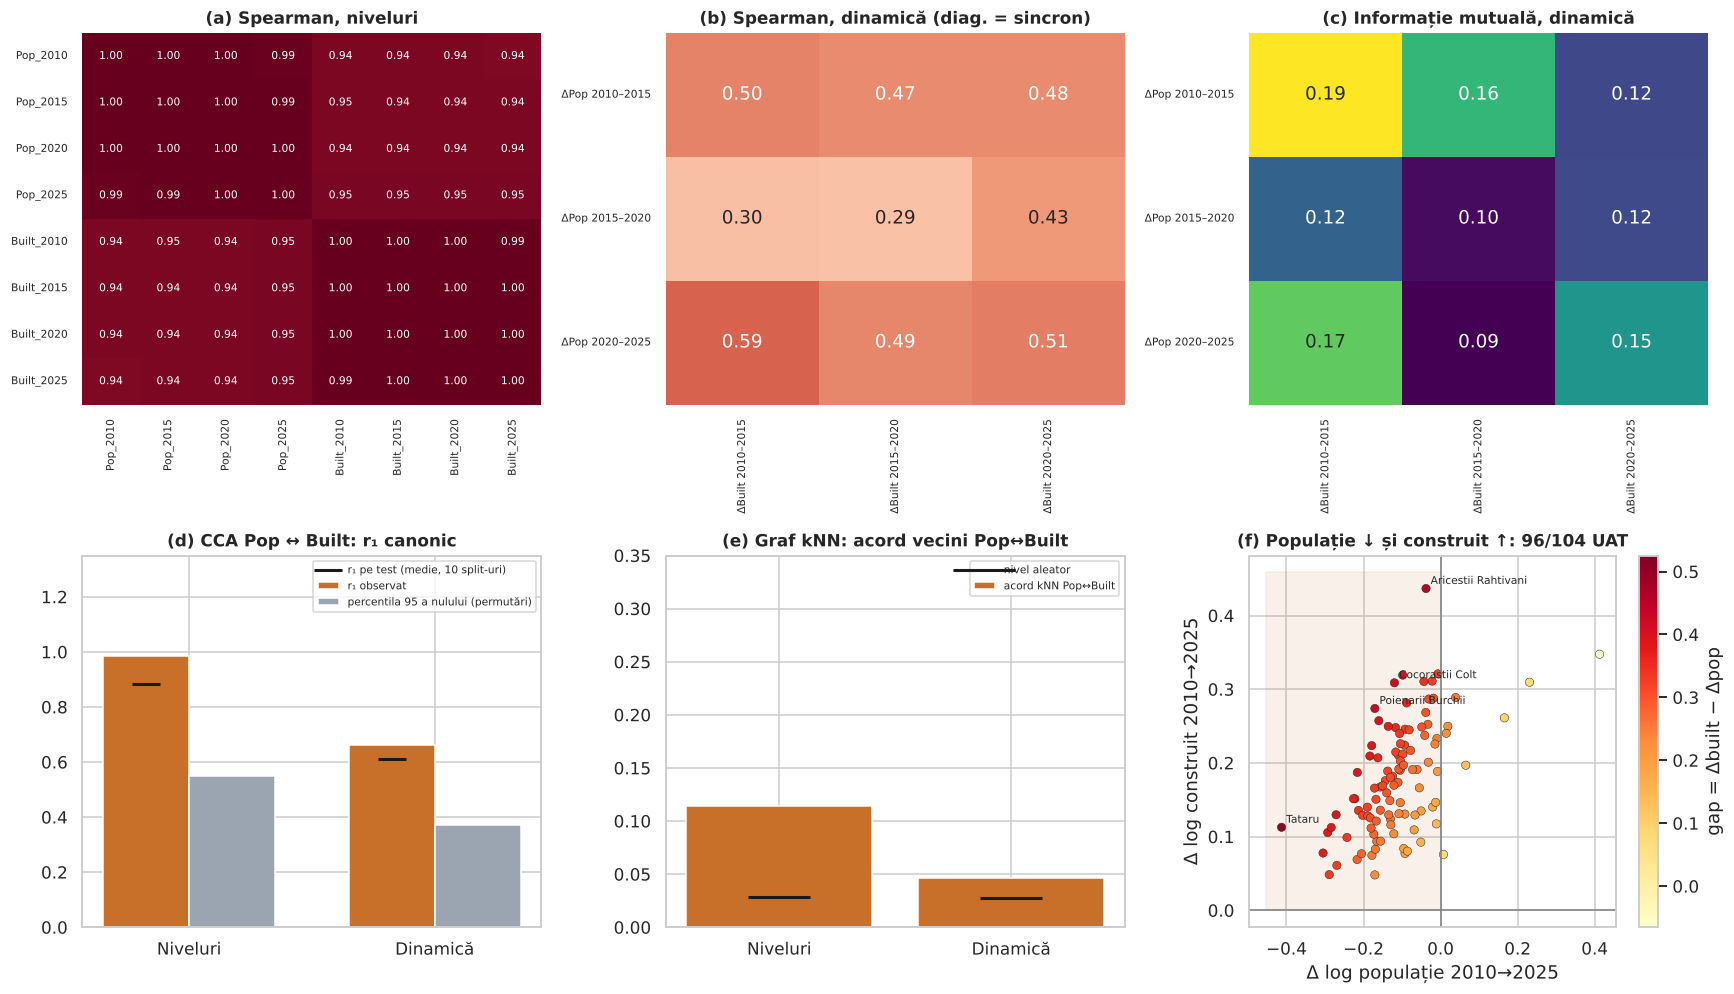

In [4]:
# ---- Figura "Harta relațiilor" ----
fig, ax = plt.subplots(2, 3, figsize=(16, 9.2))
sns.heatmap(R_lev, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax[0, 0], cbar=False, annot_kws={"size": 7})
ax[0, 0].set_title("(a) Spearman, niveluri", fontsize=11)
sns.heatmap(lag_corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax[0, 1], cbar=False)
ax[0, 1].set_title("(b) Spearman, dinamică (diag. = sincron)", fontsize=11)
sns.heatmap(MI_dyn, annot=True, fmt=".2f", cmap="viridis", ax=ax[0, 2], cbar=False)
ax[0, 2].set_title("(c) Informație mutuală, dinamică", fontsize=11)
for a in ax[0, :]: a.tick_params(axis="both", labelsize=7)

x = np.arange(len(cca_tab)); w = 0.35
ax[1, 0].bar(x - w/2, cca_tab.r1, w, label="r₁ observat", color="#C8702A")
ax[1, 0].bar(x + w/2, cca_tab.null95, w, label="percentila 95 a nulului (permutări)", color="#9AA5B1")
ax[1, 0].plot(x - w/2, cca_tab.r1_test_medie, "k_", ms=18, mew=2, label="r₁ pe test (medie, 10 split-uri)")
ax[1, 0].set_xticks(x); ax[1, 0].set_xticklabels(cca_tab.index); ax[1, 0].set_ylim(0, 1.05)
ax[1, 0].set_title("(d) CCA Pop ↔ Built: r₁ canonic", fontsize=11); ax[1, 0].set_ylim(0, 1.35); ax[1, 0].legend(fontsize=7, loc="upper right", ncol=1)

ax[1, 1].bar(knn_tab.index, knn_tab.jaccard_Pop_vs_Built, color="#C8702A", label="acord kNN Pop↔Built")
ax[1, 1].plot(knn_tab.index, knn_tab.jaccard_aleator, "k_", ms=40, mew=2, label="nivel aleator")
ax[1, 1].set_title("(e) Graf kNN: acord vecini Pop↔Built", fontsize=11); ax[1, 1].set_ylim(0, 0.35); ax[1, 1].legend(fontsize=7, loc="upper right")

sc = ax[1, 2].scatter(df.dPop_tot, df.dBuilt_tot, c=df.gap, cmap="YlOrRd", s=30, edgecolor="k", lw=0.3)
ax[1, 2].axvline(0, color="grey", lw=1); ax[1, 2].axhline(0, color="grey", lw=1)
ax[1, 2].fill_betweenx([0, ax[1, 2].get_ylim()[1]], ax[1, 2].get_xlim()[0], 0, color="#C8702A", alpha=0.10)
ax[1, 2].set_xlabel("Δ log populație 2010→2025"); ax[1, 2].set_ylabel("Δ log construit 2010→2025")
ax[1, 2].set_title(f"(f) Populație ↓ și construit ↑: {pop_down_built_up.sum()}/104 UAT", fontsize=11)
for i in df.nlargest(4, "gap").index:
    ax[1, 2].annotate(df.UAT_Name[i].replace("Oras ", "").replace("Municipiul ", ""), (df.dPop_tot[i], df.dBuilt_tot[i]), fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.colorbar(sc, ax=ax[1, 2], label="gap = Δbuilt − Δpop")
plt.tight_layout(); plt.savefig("figures/harta_relatiilor.png", dpi=200, bbox_inches="tight"); plt.show()

**Cum se citește.** În *niveluri*, Pop și Built sunt aproape redundante (ambele măsoară mărimea UAT; panoul a, d, e). În *dinamică* legătura dintre surse este mult mai slabă (panourile b, c, d), deci Built aduce informație **nouă** față de populație exact pe întrebarea noastră (panoul f).

## 3. Protocolul experimental (identic pentru toate metodele)

| Element | Alegere |
|---|---|
| **Unitate / X** | 104 UAT × trăsături. *Niveluri*: Pop_t, Built_t (t=2010…2025) → 4 + 4 = 8 trăsături (matricea X din CP2). *Dinamică*: log-rate pe 3 intervale de 5 ani → 3 + 3 = 6 trăsături |
| **Vederi** | **Pop** (doar Eurostat), **Built** (doar GHSL), **Pop+Built** (concatenare = date combinate) |
| **Metode** | **PCA** (baseline liniar), **t-SNE** (neliniar, local), **Autoencoder** (învățat; MLP d–8–k–8–d, tanh). Pentru relația dintre surse (multi-view): **CCA** (secțiunea 2) |
| **Dimensiune** | k = 2 pentru toate metodele (comparabil și vizualizabil); k se rafinează prin ablație la CP4 |
| **Split** | Aleator 80/20 pe UAT-uri, repetat cu 10 seed-uri. *Scaler-ul și reducerea se potrivesc (fit) doar pe train* și se aplică pe test (fără leakage). Spațial nu e posibil: nu avem coordonate/vecinătăți în tabele |
| **t-SNE out-of-sample** | t-SNE nu are `transform`; UAT-urile de test sunt plasate prin interpolare kNN (k=5, pondere 1/distanță) față de UAT-urile de train în spațiul de intrare. Se raportează ca atare |
| **Metrici** | *Locală*: trustworthiness (k=5) și continuity (k=5) pe test. *Globală*: corelația Spearman dintre distanțele din X și din Z. *Reconstrucție*: R² de reconstrucție pe test (PCA = varianță explicată pe test, Autoencoder; n/a pentru t-SNE). *Varianță explicată* PCA pe train |
| **Stabilitate – seed-uri** | 10 seed-uri (split + inițializare t-SNE/AE). Raportăm media și intervalul de încredere 95% (t-Student). În plus: acordul kNN (Jaccard) între embeddingurile din seed-uri diferite |
| **Stabilitate – subperioade** | Aceleași metode pe fereastra **P1** (2010–2020) și **P2** (2015–2025): diferența de trustworthiness (P2−P1) și acordul kNN între cele două embeddinguri |
| **Baseline** | PCA pe același split, același k, aceleași metrici. Dacă alternativa nu bate PCA, acesta este rezultatul |

In [5]:
def trust_cont(Xs, Z, k=KNN):
    # trustworthiness și continuity (continuity = trustworthiness cu rolurile inversate)
    k = int(min(k, max(1, len(Xs) // 2 - 1)))
    return trustworthiness(Xs, Z, n_neighbors=k), trustworthiness(Z, Xs, n_neighbors=k)

def fit_reducer(method, Xtr, k, seed):
    # Xtr standardizat. Întoarce (encode, decode|None, Z_train). Totul se potrivește DOAR pe train.
    if method == "PCA":
        m = PCA(n_components=k, random_state=seed).fit(Xtr)
        return m.transform, m.inverse_transform, m.transform(Xtr)
    if method == "t-SNE":
        emb = TSNE(n_components=k, perplexity=10, init="random", learning_rate="auto", max_iter=750, random_state=seed).fit_transform(Xtr)
        ext = KNeighborsRegressor(n_neighbors=5, weights="distance").fit(Xtr, emb)
        return ext.predict, None, emb
    if method == "Autoencoder":
        ae = MLPRegressor(hidden_layer_sizes=(8, k, 8), activation="tanh", solver="lbfgs", alpha=1e-3, max_iter=3000, random_state=seed).fit(Xtr, Xtr)
        enc = lambda Z: np.tanh(np.tanh(Z @ ae.coefs_[0] + ae.intercepts_[0]) @ ae.coefs_[1] + ae.intercepts_[1])
        dec = lambda C: np.tanh(C @ ae.coefs_[2] + ae.intercepts_[2]) @ ae.coefs_[3] + ae.intercepts_[3]   # cod (k) -> reconstrucție (d)
        return enc, dec, enc(Xtr)
    raise ValueError(method)

def eval_split(Xraw_tr, Xraw_te, method, k, seed):
    sc = StandardScaler().fit(Xraw_tr)                     # scaler doar pe train
    Xtr, Xte = sc.transform(Xraw_tr), sc.transform(Xraw_te)
    enc, dec, _ = fit_reducer(method, Xtr, k, seed)
    Zte = enc(Xte)
    t, c = trust_cont(Xte, Zte)
    out = dict(trust=t, cont=c, dist_rho=stats.spearmanr(pdist(Xte), pdist(Zte))[0], recon_r2=np.nan)
    if dec is not None:
        out["recon_r2"] = 1 - np.sum((Xte - dec(Zte)) ** 2) / np.sum(Xte ** 2)
    if method == "PCA":
        out["var_expl_train"] = PCA(n_components=k).fit(Xtr).explained_variance_ratio_.sum()
        out["var_expl_k1"]    = PCA(n_components=1).fit(Xtr).explained_variance_ratio_.sum()
    return out

def ci95(x):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    return stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan

def summarize(d, by, cols):
    g = d.groupby(by)[cols]
    return g.mean().join(g.agg(ci95), rsuffix="_ci")
print("Funcții de protocol definite.")

Funcții de protocol definite.


## 4. Rezultat principal: reprezentări vs. PCA, pe seed-uri, cu intervale
Același split (80/20), aceleași metrici, 10 seed-uri, pentru fiecare sursă separat și pentru date combinate.

In [6]:
t0 = time.time()
rows = []
for sp in SPACES:
    for view in ["Pop", "Built", "Pop+Built"]:
        X_all = df[view_cols(sp, view)].values
        for s in SEEDS:
            tr, te = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, random_state=s)
            for m in METHODS:
                rows.append(dict(spatiu=sp, vedere=view, metoda=m, seed=s, **eval_split(X_all[tr], X_all[te], m, K_DIM, s)))
res = pd.DataFrame(rows)
res.to_csv("results/cp3_rezultate_brute.csv", index=False)
print(f"{len(res)} rulări în {time.time()-t0:.0f}s")

main = summarize(res, ["spatiu", "vedere", "metoda"], ["trust", "cont", "dist_rho", "recon_r2"]).reset_index()
main.to_csv("results/cp3_tabel_principal.csv", index=False)

def fmt(r, c, d=3): return "n/a" if pd.isna(r[c]) else f"{r[c]:.{d}f} ± {r[c+'_ci']:.{d}f}"
tabel = main.assign(val=main.apply(lambda r: fmt(r, "trust"), axis=1)).pivot(index="metoda", columns=["spatiu", "vedere"], values="val").reindex(METHODS)
print("Trustworthiness pe test (k=5), medie ± IC95 peste 10 seed-uri")
display(tabel)

180 rulări în 26s
Trustworthiness pe test (k=5), medie ± IC95 peste 10 seed-uri


spatiu            Dinamică                                     Niveluri                              
vedere               Built            Pop      Pop+Built          Built            Pop      Pop+Built
metoda                                                                                               
PCA          0.981 ± 0.011  0.955 ± 0.011  0.947 ± 0.019  1.000 ± 0.000  1.000 ± 0.000  0.999 ± 0.001
t-SNE        0.938 ± 0.017  0.893 ± 0.023  0.872 ± 0.014  0.965 ± 0.019  0.958 ± 0.018  0.956 ± 0.018
Autoencoder  0.939 ± 0.029  0.925 ± 0.019  0.856 ± 0.037  0.993 ± 0.007  0.998 ± 0.001  0.968 ± 0.020

In [7]:
# Cine bate baseline-ul PCA? Diferență pereche pe seed (aceleași split-uri), IC95 al diferenței
piv = res.pivot_table(index=["spatiu", "vedere", "seed"], columns="metoda", values="trust")
cmp_rows = []
for (sp, v), g in piv.groupby(level=[0, 1]):
    for m in METHODS[1:]:
        d = (g[m] - g["PCA"]).values
        cmp_rows.append(dict(spatiu=sp, vedere=v, metoda=m, delta_trust_vs_PCA=d.mean(), ci95=ci95(d),
                             semnificativ="DA" if abs(d.mean()) > ci95(d) else "nu", castiga=("metoda" if d.mean() > 0 else "PCA") if abs(d.mean()) > ci95(d) else "egal"))
cmp_tab = pd.DataFrame(cmp_rows); cmp_tab.to_csv("results/cp3_delta_vs_pca.csv", index=False)
display(cmp_tab.round(4))

# Reconstrucție + varianță explicată (doar metodele cu decoder)
rec = summarize(res[res.metoda.isin(["PCA", "Autoencoder"])], ["spatiu", "vedere", "metoda"], ["recon_r2"]).reset_index()
ve  = summarize(res[res.metoda == "PCA"], ["spatiu", "vedere"], ["var_expl_k1", "var_expl_train"]).reset_index()
rec.to_csv("results/cp3_reconstructie.csv", index=False); ve.to_csv("results/cp3_varianta_pca.csv", index=False)
print("R² de reconstrucție pe test (k=2):"); display(rec.round(3))
print("Varianța explicată PCA pe train (k=1 și k=2):"); display(ve.round(3))

,spatiu,vedere,metoda,delta_trust_vs_PCA,ci95,semnificativ,castiga
0,Dinamică,Built,t-SNE,-0.0436,0.0118,DA,PCA
1,Dinamică,Built,Autoencoder,-0.0423,0.0324,DA,PCA
2,Dinamică,Pop,t-SNE,-0.0621,0.0295,DA,PCA
3,Dinamică,Pop,Autoencoder,-0.03,0.0161,DA,PCA
4,Dinamică,Pop+Built,t-SNE,-0.0755,0.0271,DA,PCA
5,Dinamică,Pop+Built,Autoencoder,-0.0918,0.0311,DA,PCA
6,Niveluri,Built,t-SNE,-0.0352,0.0186,DA,PCA
7,Niveluri,Built,Autoencoder,-0.007,0.0066,DA,PCA
8,Niveluri,Pop,t-SNE,-0.042,0.018,DA,PCA
9,Niveluri,Pop,Autoencoder,-0.0023,0.0014,DA,PCA


R² de reconstrucție pe test (k=2):


,spatiu,vedere,metoda,recon_r2,recon_r2_ci
0,Dinamică,Built,Autoencoder,0.821,0.096
1,Dinamică,Built,PCA,0.933,0.024
2,Dinamică,Pop,Autoencoder,0.818,0.09
3,Dinamică,Pop,PCA,0.856,0.043
4,Dinamică,Pop+Built,Autoencoder,0.47,0.141
5,Dinamică,Pop+Built,PCA,0.759,0.057
6,Niveluri,Built,Autoencoder,0.903,0.142
7,Niveluri,Built,PCA,1,0
8,Niveluri,Pop,Autoencoder,-1.546,5.415
9,Niveluri,Pop,PCA,1,0


Varianța explicată PCA pe train (k=1 și k=2):


,spatiu,vedere,var_expl_k1,var_expl_train,var_expl_k1_ci,var_expl_train_ci
0,Dinamică,Built,0.777,0.935,0.011,0.006
1,Dinamică,Pop,0.777,0.902,0.02,0.01
2,Dinamică,Pop+Built,0.611,0.784,0.019,0.014
3,Niveluri,Built,0.998,1,0.001,0
4,Niveluri,Pop,0.999,1,0.001,0
5,Niveluri,Pop+Built,0.973,0.999,0.011,0.001


## 5. Stabilitate: seed-uri și subperioade
- **Seed-uri**: acordul kNN (Jaccard) între embeddingurile obținute cu seed-uri diferite pe aceleași UAT-uri (PCA este deterministă ⇒ 1).
- **Subperioade**: aceleași metode pe fereastra P1 (2010–2020) vs. P2 (2015–2025). Raportăm (i) diferența de trustworthiness pe test P2−P1 și (ii) acordul kNN între embeddingurile P1 și P2 (cu seed-uri diferite), comparat cu „plafonul" din spațiul de intrare.

In [8]:
t0 = time.time()
def embed_all(cols, method, seed):
    # embedding transductiv, nesupervizat, al tuturor UAT-urilor (pentru acorduri între rulări și pentru figură)
    Xs = StandardScaler().fit_transform(df[cols].values)
    return fit_reducer(method, Xs, K_DIM, seed)[2], Xs

stab_seed, stab_win, win_tr, emb_cache = [], [], [], {}
for sp in SPACES:
    for view in ["Pop", "Built", "Pop+Built"]:
        cols = view_cols(sp, view)
        for m in METHODS:
            E = []
            for s in SEEDS:
                Z, Xs = embed_all(cols, m, s); E.append(knn_idx(Z)); emb_cache[(sp, view, m, s)] = Z
            pairs = [jaccard(E[i], E[j]) for i, j in itertools.combinations(range(len(E)), 2)]
            stab_seed.append(dict(spatiu=sp, vedere=view, metoda=m, jaccard_seed_medie=np.mean(pairs), jaccard_seed_min=np.min(pairs)))
            # subperioade
            tw = {}
            for w in ["P1", "P2"]:
                cw = view_cols(sp, view, w); Xw = df[cw].values
                tw[w] = []
                for s in SEEDS:
                    tr, te = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, random_state=s)
                    tw[w].append(eval_split(Xw[tr], Xw[te], m, K_DIM, s)["trust"])
            d = np.array(tw["P2"]) - np.array(tw["P1"])
            J = []
            for s in SEEDS:
                Z1, X1 = embed_all(view_cols(sp, view, "P1"), m, s); Z2, X2 = embed_all(view_cols(sp, view, "P2"), m, s + 1000)
                J.append(jaccard(knn_idx(Z1), knn_idx(Z2)))
            ceil = jaccard(knn_idx(X1), knn_idx(X2))
            degen = len(view_cols(sp, view, "P1")) <= K_DIM      # d <= k: PCA e fără pierderi (trust=1 prin construcție) ⇒ comparație neinformativă
            nan = np.nan
            stab_win.append(dict(spatiu=sp, vedere=view, metoda=m, d_trasaturi_fereastra=len(view_cols(sp, view, "P1")), degenerat=degen,
                                 trust_P1=nan if degen else np.mean(tw["P1"]), trust_P2=nan if degen else np.mean(tw["P2"]),
                                 delta_P2_P1=nan if degen else d.mean(), delta_ci95=nan if degen else ci95(d),
                                 jaccard_P1_P2=np.mean(J), jaccard_P1_P2_ci95=ci95(J), plafon_input=ceil))
stab_seed, stab_win = pd.DataFrame(stab_seed), pd.DataFrame(stab_win)
stab_seed.to_csv("results/cp3_stabilitate_seed.csv", index=False); stab_win.to_csv("results/cp3_stabilitate_subperioade.csv", index=False)
print(f"stabilitate calculată în {time.time()-t0:.0f}s")
print("Acord kNN între seed-uri (Jaccard; 1 = identic):")
display(stab_seed.pivot(index="metoda", columns=["spatiu", "vedere"], values="jaccard_seed_medie").reindex(METHODS).round(2))
print("Subperioade: Δ trustworthiness (P2−P1) și acord kNN P1↔P2 (NaN = degenerat: d ≤ k, PCA fără pierderi):")
display(stab_win.round(3))

stabilitate calculată în 101s
Acord kNN între seed-uri (Jaccard; 1 = identic):


spatiu      Niveluri                 Dinamică                
vedere           Pop Built Pop+Built      Pop Built Pop+Built
metoda                                                       
PCA             1.00  1.00      1.00     1.00  1.00      1.00
t-SNE           0.96  0.97      0.93     0.78  0.76      0.66
Autoencoder     0.73  0.67      0.47     0.35  0.52      0.33

Subperioade: Δ trustworthiness (P2−P1) și acord kNN P1↔P2 (NaN = degenerat: d ≤ k, PCA fără pierderi):


,spatiu,vedere,metoda,d_trasaturi_fereastra,degenerat,trust_P1,trust_P2,delta_P2_P1,delta_ci95,jaccard_P1_P2,jaccard_P1_P2_ci95,plafon_input
0,Niveluri,Pop,PCA,3,False,1,1,0,0,0.675,0,0.676
1,Niveluri,Pop,t-SNE,3,False,0.958,0.959,0.001,0.004,0.662,0.005,0.676
2,Niveluri,Pop,Autoencoder,3,False,0.998,0.997,-0.001,0.002,0.581,0.063,0.676
3,Niveluri,Built,PCA,3,False,1,1,-0,0,0.694,0,0.692
4,Niveluri,Built,t-SNE,3,False,0.964,0.965,0.001,0.005,0.694,0.007,0.692
5,Niveluri,Built,Autoencoder,3,False,0.995,0.997,0.002,0.004,0.647,0.044,0.692
6,Niveluri,Pop+Built,PCA,6,False,1,1,0,0,0.723,0,0.719
7,Niveluri,Pop+Built,t-SNE,6,False,0.959,0.957,-0.002,0.005,0.672,0.006,0.719
8,Niveluri,Pop+Built,Autoencoder,6,False,0.962,0.957,-0.005,0.018,0.396,0.109,0.719
9,Dinamică,Pop,PCA,2,True,NaN,NaN,NaN,NaN,0.179,0,0.179


## 6. Figuri: reprezentările pe fiecare sursă și pe datele combinate
Culoarea = indicele de decuplare `gap = Δ log construit − Δ log populație` (2010→2025): UAT-urile închise la culoare cresc în construit mai repede decât în populație. Embeddingurile sunt cele ale seed-ului 0 pe toate UAT-urile (transductiv, nesupervizat).

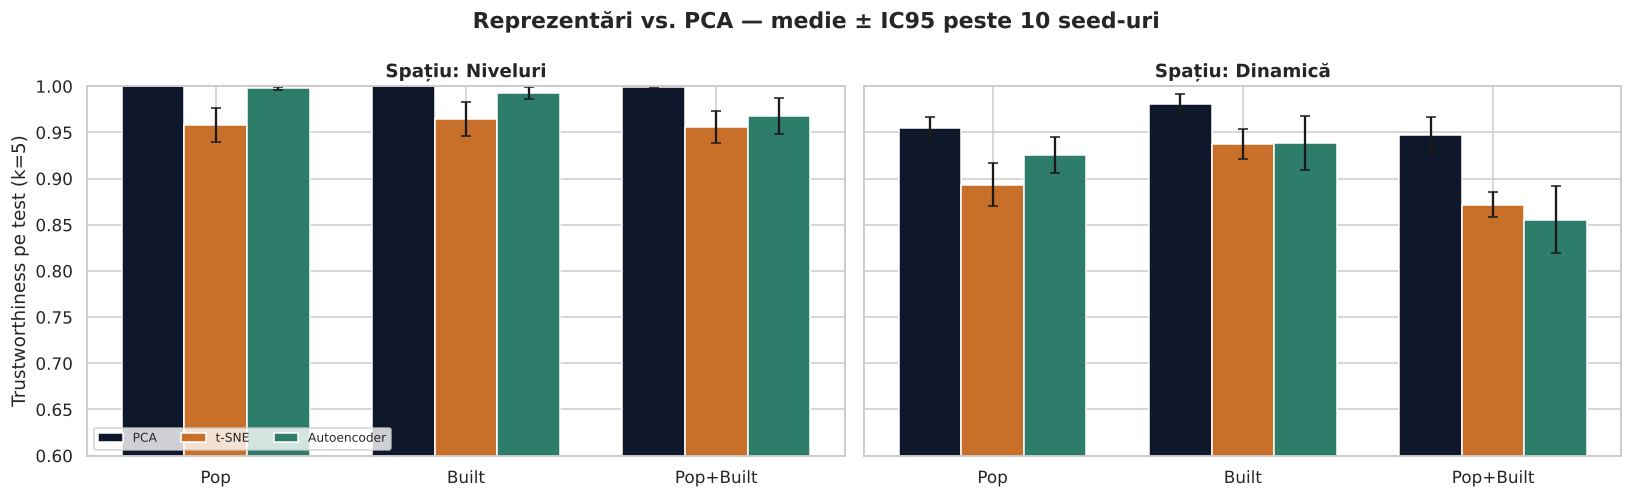

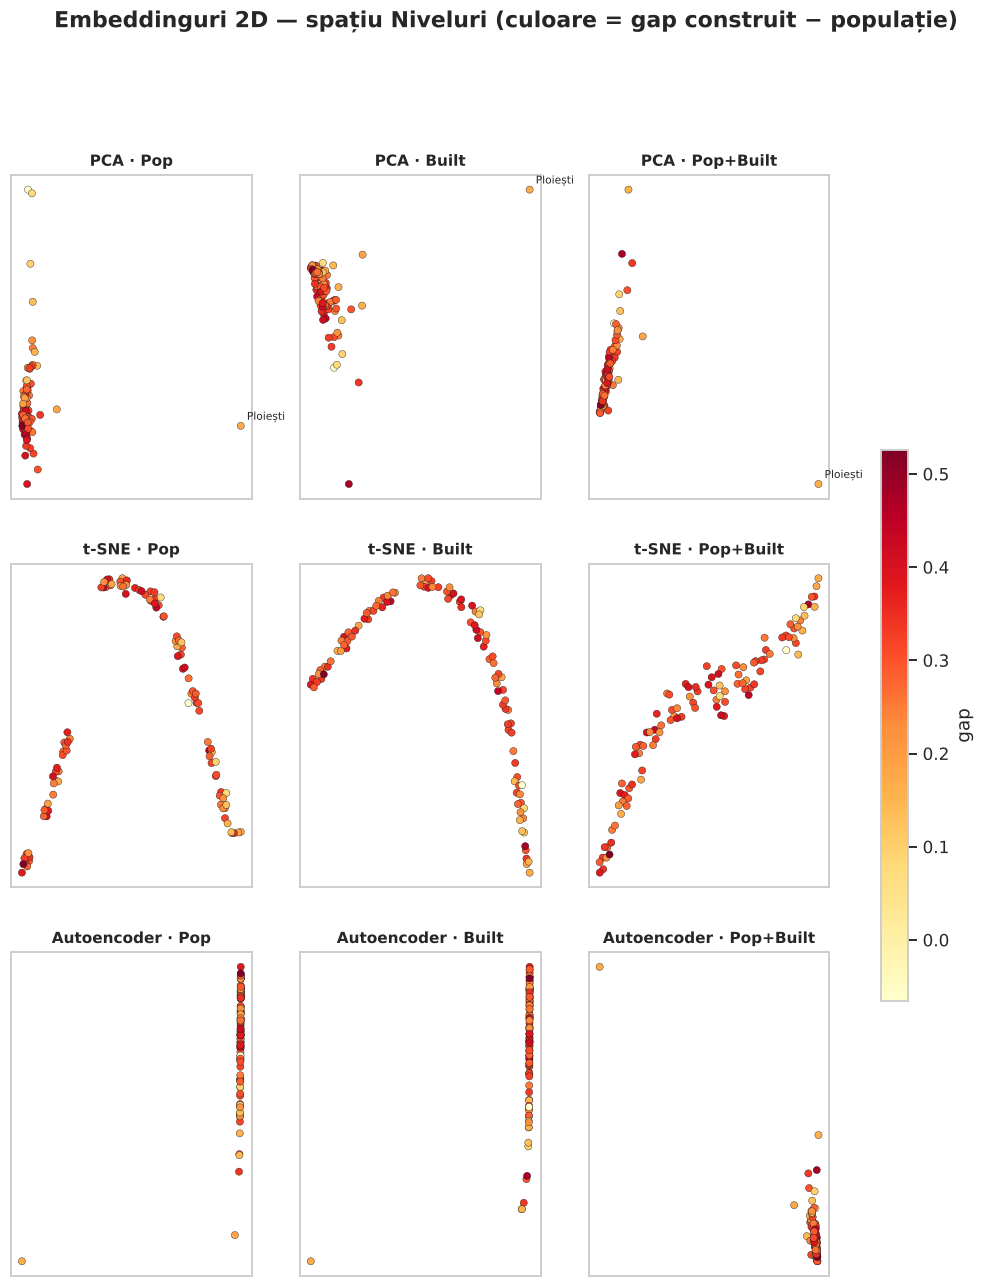

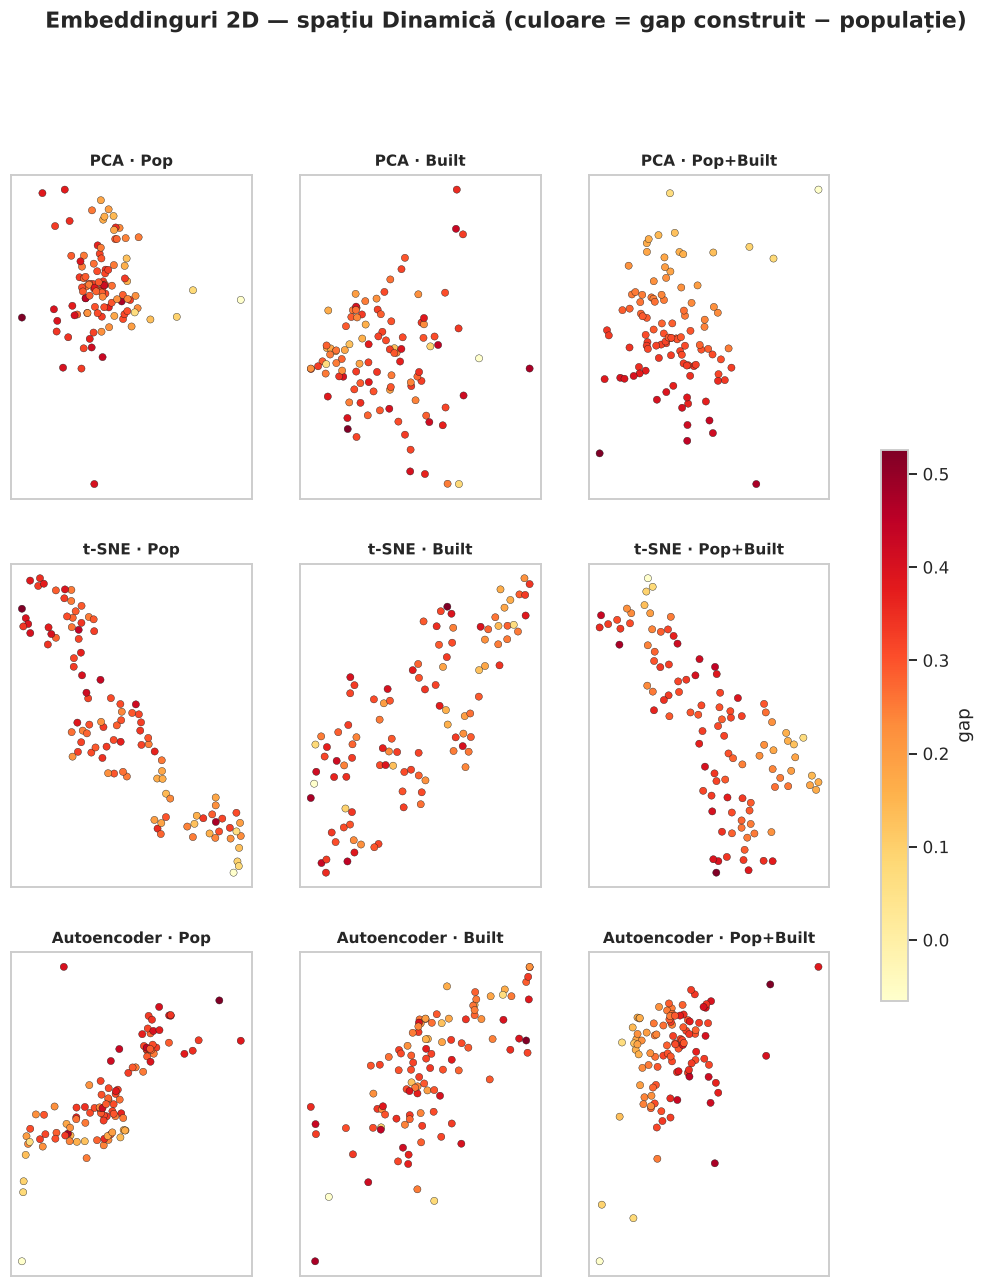

In [9]:
# ---- Figura A: tabelul principal ca bare cu IC95 ----
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
pal = {"PCA": "#0F172A", "t-SNE": "#C8702A", "Autoencoder": "#2E7D6B"}
for ax, sp in zip(axes, SPACES):
    d = main[main.spatiu == sp]; x = np.arange(3); w = 0.25
    for i, m in enumerate(METHODS):
        dm = d[d.metoda == m].set_index("vedere").loc[["Pop", "Built", "Pop+Built"]]
        ax.bar(x + (i - 1) * w, dm.trust, w, yerr=dm.trust_ci, capsize=3, color=pal[m], label=m)
    ax.set_xticks(x); ax.set_xticklabels(["Pop", "Built", "Pop+Built"]); ax.set_title(f"Spațiu: {sp}"); ax.set_ylim(0.6, 1.0)
axes[0].set_ylabel("Trustworthiness pe test (k=5)"); axes[0].legend(ncol=3, fontsize=8, loc="lower left")
plt.suptitle("Reprezentări vs. PCA — medie ± IC95 peste 10 seed-uri", fontweight="bold"); plt.tight_layout()
plt.savefig("figures/tabel_principal_trust.png", dpi=200, bbox_inches="tight"); plt.show()

# ---- Figura B: embeddinguri 2D, metodă × vedere (spațiul Dinamică și Niveluri) ----
for sp in SPACES:
    fig, axes = plt.subplots(len(METHODS), 3, figsize=(12, 13), squeeze=False)
    for i, m in enumerate(METHODS):
        for j, v in enumerate(["Pop", "Built", "Pop+Built"]):
            Z = emb_cache[(sp, v, m, 0)]
            sc = axes[i, j].scatter(Z[:, 0], Z[:, 1], c=df.gap, cmap="YlOrRd", s=22, edgecolor="k", lw=0.25)
            axes[i, j].set_title(f"{m} · {v}", fontsize=10); axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
            if m == "PCA" and sp == "Niveluri":
                axes[i, j].annotate("Ploiești", Z[df.UAT_Name.str.contains("Ploiesti").values][0], fontsize=7, xytext=(4, 4), textcoords="offset points")
    plt.suptitle(f"Embeddinguri 2D — spațiu {sp} (culoare = gap construit − populație)", fontweight="bold", y=0.995)
    fig.colorbar(sc, ax=axes, shrink=0.5, label="gap"); plt.savefig(f"figures/embeddinguri_{sp.lower().replace('ă','a')}.png", dpi=170, bbox_inches="tight"); plt.show()

## 7. Sinteză și concluzii CP3

In [10]:
def best_of(sp, view):
    d = main[(main.spatiu == sp) & (main.vedere == view)].set_index("metoda")
    return d.trust.idxmax(), d.trust.max(), d.loc["PCA", "trust"]

print("=== Sinteză automată ===")
for sp in SPACES:
    for v in ["Pop", "Built", "Pop+Built"]:
        b, tb, tp = best_of(sp, v)
        sig = cmp_tab[(cmp_tab.spatiu == sp) & (cmp_tab.vedere == v) & (cmp_tab.metoda == b)]
        extra = "" if b == "PCA" else f" | Δ vs PCA = {sig.delta_trust_vs_PCA.iloc[0]:+.3f} ± {sig.ci95.iloc[0]:.3f} ({'semnificativ' if sig.semnificativ.iloc[0]=='DA' else 'nesemnificativ'})"
        print(f"{sp:9s} {v:10s} → cea mai bună: {b:12s} trust={tb:.3f} (PCA={tp:.3f}){extra}")
print()
n_cmp = len(cmp_tab); n_win = (cmp_tab.castiga == "metoda").sum(); n_pca = (cmp_tab.castiga == "PCA").sum(); n_eq = (cmp_tab.castiga == "egal").sum()
print(f"Comparații metodă-neliniară vs PCA: {n_cmp} | câștigate de metodă: {n_win} | câștigate de PCA (semnificativ): {n_pca} | egale: {n_eq}")
print("CCA:", cca_tab[["r1", "null95", "p_perm", "r1_test_medie"]].round(3).to_dict("index"))
print(f"UAT cu populație ↓ și construit ↑ (2010→2025): {pop_down_built_up.sum()} / {len(df)}")
print("Top 5 UAT după gap (construit crește mai mult decât populația):")
display(df.nlargest(5, "gap")[["UAT_Name", "Pop_2010", "Pop_2025", "Built_2010", "Built_2025", "gap"]].round(3))

=== Sinteză automată ===
Niveluri  Pop        → cea mai bună: PCA          trust=1.000 (PCA=1.000)
Niveluri  Built      → cea mai bună: PCA          trust=1.000 (PCA=1.000)
Niveluri  Pop+Built  → cea mai bună: PCA          trust=0.999 (PCA=0.999)
Dinamică  Pop        → cea mai bună: PCA          trust=0.955 (PCA=0.955)
Dinamică  Built      → cea mai bună: PCA          trust=0.981 (PCA=0.981)
Dinamică  Pop+Built  → cea mai bună: PCA          trust=0.947 (PCA=0.947)

Comparații metodă-neliniară vs PCA: 12 | câștigate de metodă: 0 | câștigate de PCA (semnificativ): 12 | egale: 0
CCA: {'Niveluri': {'r1': 0.986, 'null95': 0.549, 'p_perm': 0.002, 'r1_test_medie': 0.883}, 'Dinamică': {'r1': 0.661, 'null95': 0.373, 'p_perm': 0.002, 'r1_test_medie': 0.611}}
UAT cu populație ↓ și construit ↑ (2010→2025): 96 / 104
Top 5 UAT după gap (construit crește mai mult decât populația):


,UAT_Name,Pop_2010,Pop_2025,Built_2010,Built_2025,gap
94,Tataru,1097,726,0.185,0.207,0.525
18,Aricestii Rahtivani,8342,8033,1.455,2.251,0.474
74,Poienarii Burchii,5254,4430,0.691,0.909,0.445
39,Cocorastii Colt,3189,2829,0.345,0.469,0.429
98,Tomsani,4591,4161,0.564,0.777,0.418


### Concluzii (cifrele provin din rularea de mai sus, 10 seed-uri)
1. **Relații.** Pop și Built sunt aproape redundante în *niveluri* (Spearman ≈ 0,94; CCA r₁ = 0,99; ambele măsoară mărimea UAT). În *dinamică* legătura scade la r₁ = 0,66 (CCA, p < 0,01 la permutări; 0,61 pe test), iar acordul vecinilor kNN Pop↔Built este aproape de nivelul aleator (Jaccard 0,05 vs 0,03). **Built aduce informație nouă față de populație tocmai în spațiul care răspunde întrebării.**
2. **Baseline.** PCA nu este depășit: din 12 comparații (2 metode × 3 vederi × 2 spații), 0 sunt câștigate de metoda neliniară; PCA câștigă semnificativ în toate 12. Rezultatul „nu bate baseline-ul” este raportat ca atare.
3. **Reconstrucție.** PCA reconstruiește mai bine decât autoencoderul pe test; autoencoderul cu activare `tanh` saturează pe valorile extreme (Ploiești) — în seed-urile în care Ploiești cade în test, R² devine puternic negativ (niveluri/Pop).
4. **Stabilitate.** PCA este determinist (Jaccard 1,00 între seed-uri). t-SNE: 0,93–0,97 în niveluri, 0,66–0,78 în dinamică. Autoencoder: 0,33–0,73. Pe subperioade, trustworthiness-ul nu se schimbă semnificativ în niveluri; în dinamică Pop+Built scade ușor de la P1 la P2 (PCA −0,026 ± 0,016; t-SNE și autoencoder nesemnificativ).
5. **Limite.** Doar 4 momente de timp (subperioadele P1/P2 se suprapun parțial; pe dinamică, vederile Pop/Built au 2 trăsături ⇒ PCA k=2 e fără pierderi și comparația e neinformativă). Fără coordonate nu avem split spațial sau Moran's I. t-SNE folosește extensie kNN pentru UAT-urile de test. Criteriul binar „construit↑ & populație↓” nu discriminează (96/104), deci folosim indicele `gap`.